In [27]:
from datetime import date
from os import environ

import pandas as pd

from five_safes_tes_workbench.workbench import Workbench

from tes_omop_callers.define_cohorts import DefineConceptCohort
from tes_omop_callers.incidence_prevalence import IncidencePrevalence
from tes_omop_callers.shell_bundlers import CohortShellBundler
from tes_omop_callers.patient_profiles import AddCharacteristics, SummariseCohort
from summarised_result import SummarisedResult

from i_p_utils import load_5s_tes_incidence_result, plot_incidence_results, combine_incidence_results, plot_jittered

# Running tasks
The Five Safes TES workbench can be used to simplify running tasks in Five Safes TES (5s-TES).
The tasks generated by this package can be used to generate the required executors.

## Incidence
A basic workflow for estimating incidence is to:

1. Define an outcome cohort
2. Call `estimateIncidence`, which creates a denominator cohort and outputs the table
3. Clean up your outcome cohort tables

We can use `DefineConceptCohort` to define an outcome cohort, `IncidencePrevalence` to call `estimateIncidence`, then wrap this in a `CohortShellBundler` to automatically clean up the outcome cohort tables.

We will try to copy [this successful task](https://5s-tes.federated-research.com/Submission/GetASubmission/3541).
The single executor for that TES message is:

```json
{
    "image": "ghcr.io/health-informatics-uon/omop-r-tools:sha-9aa526d",
    "command": [
             "/bin/sh",
             "-c",
             "Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohortz1bc5nl2 --conceptSet='{\"diabetes\": [201254, 201826]}' && Rscript inst/scripts/incidencePrevalence.R denominator_z1bc5nl2 --outcomeCohortName=diabetes_cohortz1bc5nl2 --denominatorCohortDateRange=1984-01-01,2004-01-01 --estimateIncidenceOutputPath=outputs/incidence.csv && Rscript inst/scripts/cleanUpCohortTables.R diabetes_cohortz1bc5nl2 && Rscript inst/scripts/cleanUpCohortTables.R denominator_z1bc5nl2"
    ],
    "workdir": null,
    "stdin": null,
    "stdout": null,
    "stderr": null,
    "env": null
}
```

The parts of this are:
1. calling the `R` script `inst/scripts/defineConceptCohortSet.R` with the parameters
    - cohort name diabetes_cohortz1bc5nl2
    - `--conceptSet='{\"diabetes\": [201254, 201826]}'`
    - others as default
2. calling the `R` script `inst/scripts/incidencePrevalence.R` with the parameters
   - denominator cohort name denominator_z1bc5nl2
   - `--outcomeCohortName=diabetes_cohortz1bc5nl2` to match the cohort defined above
   - `--denominatorCohortDateRange=1984-01-01,2004-01-01`
   - `--estimateIncidenceOutputPath=outputs/incidence.csv`
   - others as default
3. Cleaning up diabetes_cohortz1bc5nl2 and denominator_z1bc5nl2

### Define concept cohort
I won't use the same name for the concept cohort as the example, but setting the concept set to the same is easy enough.

In [2]:
cohort_task = DefineConceptCohort(
    cohort_name="diabetes_cohort_jmw",
    concept_set={"diabetes": [201254, 201826]},
)
cohort_task.render()

'Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohort_jmw --conceptSet=\'{"diabetes": [201254, 201826]}\' --end=observation_period_end_date --requiredObservation=0,0'

The rendered task is a little different from the example, as it sets `--end=observation_period_end_date` and `--requiredObservation=\'[0,0]\'`, which are the defaults, so that's fine.

### Incidence
Again, I won't use quite the same names as the example, but will set the other arguments to match.

In [3]:
incidence_task = IncidencePrevalence(
    outcome_cohort_name="diabetes_cohort_jmw",
    denominator_cohort_name="denominator_jmw",
    denominator_cohort_date_range=(
        date(
            1984,
            1,
            1,
        ),
        date(2004, 1, 1),
    ),
    estimate_incidence_output_path="outputs/incidence.csv",
    # defaults
)
incidence_task.render()

"Rscript inst/scripts/incidencePrevalence.R denominator_jmw --denominatorCohortDateRange=1984-01-01,2004-01-01 --denominatorAgeGroup='[[0, 150]]' --denominatorDaysPriorObservation=0 --outcomeCohortName=diabetes_cohort_jmw --estimateIncidenceOutputPath=outputs/incidence.csv --incidenceInterval=years --incidenceOutcomeWashout=0 --pointPrevalenceInterval=years --pointPrevalenceTimePoint=start --periodPrevalenceInterval=years"

Again, there are a few extras, but these are the defaults, so won't change any behaviour.
I'm keeping it generating the defaults, as the CLI defaults for the scripts might change at the other end, so the way to keep things consistent at this end is to be explicit.
This makes for longer strings, but this is all hiding stuff from view anyway, so I'm OK with it.

The `outcomeCohortName`, `denominatorCohortDateRange`, and `estimateIncidenceOutputPath` are as expected.

### Bundled TES message
Tying the tasks together with a `CohortShellBundler` should render a similar message to the example.

In [4]:
incidence_bundler = CohortShellBundler(
    image="ghcr.io/health-informatics-uon/omop-r-tools:sha-7bb8764",
    tasks=[cohort_task, incidence_task],
)

incidence_bundler.render_executor()

{'image': 'ghcr.io/health-informatics-uon/omop-r-tools:sha-7bb8764',
 'command': ['bin/sh',
  '-c',
  'Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohort_jmw --conceptSet=\'{"diabetes": [201254, 201826]}\' --end=observation_period_end_date --requiredObservation=0,0 && Rscript inst/scripts/incidencePrevalence.R denominator_jmw --denominatorCohortDateRange=1984-01-01,2004-01-01 --denominatorAgeGroup=\'[[0, 150]]\' --denominatorDaysPriorObservation=0 --outcomeCohortName=diabetes_cohort_jmw --estimateIncidenceOutputPath=outputs/incidence.csv --incidenceInterval=years --incidenceOutcomeWashout=0 --pointPrevalenceInterval=years --pointPrevalenceTimePoint=start --periodPrevalenceInterval=years; Rscript inst/scripts/cleanUpCohortTables.R denominator_jmw diabetes_cohort_jmw']}

The commands are what we were looking for.
The bundler has automatically made the task to clean up the cohorts we want at the end.
A slight difference with the example task is that this happens in a single call of `cleanUpCohortTables`, which means we have to use a different version of the container.

This also uses a semicolon, rather than `&&` to separate this task from the previous, as we want it to run, regardless of whether a previous task fails.

### Will it run?
Making some JSON is all well and good, but does it work?

I'll start the workbench and validate my credentials.

In [42]:
wb = Workbench()
wb.validate(
    project="OHDSIDemo",
    tres=["Nottingham TRE 01", "Nottingham TRE 02"],
    tes_base_url="https://api.5s-tes.federated-research.com/",
    keycloak_url="https://drs-core-identity.azurewebsites.net/",
    client_id="Dare-Control-S3",
    # Enter your own API key, username, and password
    client_secret=environ["TES_KEY"],
    username=environ["TES_USER"],
    password=environ["TES_PASSWORD"],
)

INFO | Template registered: 'hello_world'
INFO | Template registered: 'custom'
INFO | Template registered: 'simple_sql'
INFO | Template registered: 'bunny'
INFO | Template registered: 'analysis'
INFO | Validation successful
INFO | Config: project='OHDSIDemo' tes_base_url='https://api.5s-tes.federated-research.com/' tres=['Nottingham TRE 01', 'Nottingham TRE 02']
INFO | Auth mode: AuthMode.CREDENTIALS


Then make a TES message that uses the executor from the bundler.

In [6]:
wb.build_tes.custom(
    name="Test python OMOP client",
    description="Testing the incidence omop caller",
    executors=[incidence_bundler.render_executor()],
    outputs=[
        {
            "name": "Analysis Results Location",
            "description": "Analysis Results Location",
            "url": "s3://",
            "path": "/outputs",
            "type": "DIRECTORY",
        }
    ],
)

INFO | Building TES task from template: 'custom'
INFO | Resolving template: 'custom'
INFO | TES Task built successfully
INFO | TES payload:
{
   "name": "Test python OMOP client",
   "description": "Testing the incidence omop caller",
   "outputs": [
      {
         "url": "s3://",
         "path": "/outputs",
         "type": "DIRECTORY",
         "name": "Analysis Results Location",
         "description": "Analysis Results Location"
      }
   ],
   "executors": [
      {
         "image": "ghcr.io/health-informatics-uon/omop-r-tools:sha-7bb8764",
         "command": [
            "bin/sh",
            "-c",
            "Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohort_jmw --conceptSet='{\"diabetes\": [201254, 201826]}' --end=observation_period_end_date --requiredObservation=0,0 && Rscript inst/scripts/incidencePrevalence.R denominator_jmw --denominatorCohortDateRange=1984-01-01,2004-01-01 --denominatorAgeGroup='[[0, 150]]' --denominatorDaysPriorObservation=0 --outcome

And submit.

In [7]:
wb.submit()

INFO | Fetching token from Keycloak...
INFO | Requesting Keycloak token from https://drs-core-identity.azurewebsites.net/realms/Dare-Control/protocol/openid-connect/token
INFO | Keycloak token fetched successfully
INFO | Task submitted successfully! ID: 3864


'3864'

In [14]:
incidence_output = wb.fetch_outputs()

INFO | Fetching Keycloak ID token for STS exchange...
INFO | Requesting Keycloak token from https://drs-core-identity.azurewebsites.net/realms/Dare-Control/protocol/openid-connect/token
INFO | Keycloak token fetched successfully
INFO | Exchanging bearer token for MinIO credentials via STS (https://api.s3.5s-tes.federated-research.com)
INFO | MinIO client initialized (endpoint=https://api.s3.5s-tes.federated-research.com, secure=True)
INFO | Child task info: 3865, TRE: Nottingham TRE 01, status: Completed
INFO | Found 1 result object(s) for task 3865
INFO | Downloading result object: 3865/incidence.csv
INFO | Downloaded 3865/incidence.csv -> /Users/jamesmitchell-white/Documents/GitHub/5s-TES-notebooks/Darwin-EU/output/Nottingham TRE 01/3865/incidence.csv
INFO | Child task info: 3866, TRE: Nottingham TRE 02, status: Completed
INFO | Found 1 result object(s) for task 3866
INFO | Downloading result object: 3866/incidence.csv
INFO | Downloaded 3866/incidence.csv -> /Users/jamesmitchell-whit

Then we can plot the results, too.

/Users/jamesmitchell-white/Documents/GitHub/5s-TES-notebooks/.venv/lib/python3.13/site-packages/incidence_prevalence/plots.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=30, ha="right")
/Users/jamesmitchell-white/Documents/GitHub/5s-TES-notebooks/.venv/lib/python3.13/site-packages/incidence_prevalence/plots.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plot.set_xticklabels(plot.get_xticklabels(), rotation=30, ha="right")


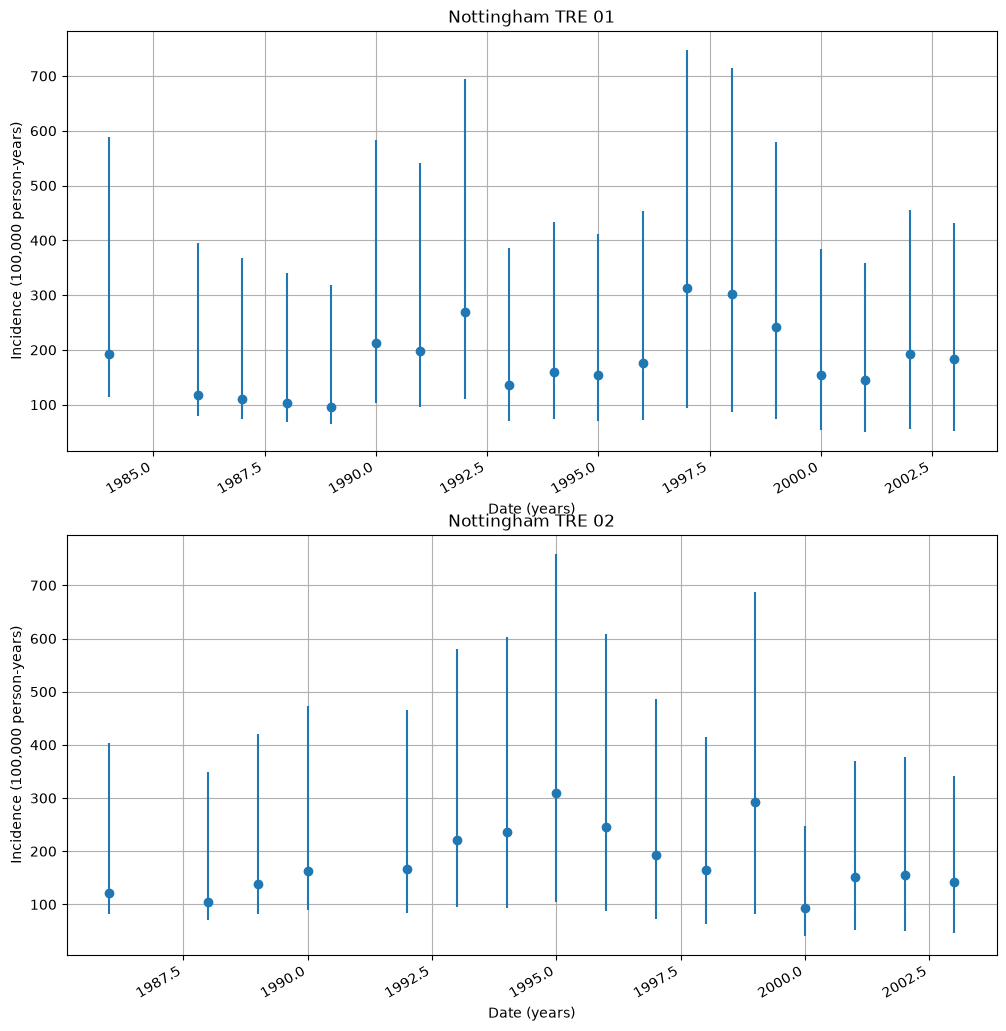

In [15]:
# Read the outputs into the notebook and wrangle them into the right shape for analysis
incidence_results = load_5s_tes_incidence_result(incidence_output)

# Plot the results
plot_incidence_results(incidence_results)

## PatientProfiles
There's an [example](https://5s-tes.federated-research.com/Submission/GetASubmission/3535) for a task adding characteristics with PatientProfiles too.
We can use the existing cohort task, but add:
1. `addCharacteristics`
    - `--indexDate=cohort_end_date`
    - `--addAge`
    - `--ageGroup=[[0,17],[18,64],[65,150]]`
    - `--ageMissingMonth=6`
    - `--ageMissingDay=15`
    - `--ageImposeMonth`
    - `--ageImposeDay`
    - `--addSex`
    - `--addPriorObservation`
    - `--addFutureObservation`
    - `--addInObservation`
    - `--inObservationWindow=[0,30]`
    - `--completeInterval`
    - `--useDemographics`
3. `summariseCohorts`
    - `--variables=[\"age\",\"sex\",\"prior_observation\",\"future_observation\",\"in_observation\"]`
    - `--estimates=[\"count\",\"percentage\",\"median\",\"q25\",\"q75\"]`
    - `--output-path=outputs/patient-characteristics.csv`

### `addCharacteristics`

The example uses a lot of non-defaults.

The default message would like like

In [16]:
AddCharacteristics(cohort_name="diabetes_jmw").render()

"Rscript inst/scripts/addCharacteristics.R diabetes_jmw --indexDate=cohort_start_date --ageGroup='[[0, 150]]' --ageName=age --inObservationWindow='[[0, 0]]'"

but there are a bunch of flags used in the example.

In [17]:
add_char_task = AddCharacteristics(
    cohort_name="diabetes_cohort_jmw",
    index_date="cohort_end_date",
    add_age=True,
    age_group=[(0,17), (18,64), (65,150)],
    missing_month=6,
    missing_day=15,
    age_impose_month=True,
    age_impose_day=True,
    add_sex=True,
    add_prior_observation=True,
    add_future_observation=True,
    add_in_observation=True,
    in_observation_window=[(0,30)],
    complete_interval=True,
    use_demographics=True
)

add_char_task.render()

"Rscript inst/scripts/addCharacteristics.R diabetes_cohort_jmw --indexDate=cohort_end_date --addAge --ageGroup='[[0, 17], [18, 64], [65, 150]]' --ageName=age --ageMissingMonth=6 --ageMissingDay=15 --ageImposeMonth --ageImposeDay --addSex --addPriorObservation --addFutureObservation --addInObservation --inObservationWindow='[[0, 30]]' --completeInterval --useDemographics"

- `--indexDate=cohort_end_date`
- `--addAge`
- `--ageGroup='[[0, 17], [18, 64], [65, 150]]'` - this has been escaped, and has spaces, which should be fine.
- `--ageName=age` - not specified in the example, but this is the default.
- `--ageMissingMonth=6`
- `--ageMissingDay=15`
- `--ageImposeMonth`
- `--ageImposeDay`
- `--addSex`
- `--addPriorObservation`
- `--addFutureObservation`
- `--addInObservation`
- `--inObservationWindow='[[0, 30]]'` - this has been escaped, and has spaces, which should be fine.
- `--completeInterval`
- `--useDemographics`

### `summariseCohort`

I defined this with my task building metaclass function, and I don't get my type hints, but I do get a help message for the init, which is something!

In [18]:
summarise_task = SummariseCohort(
    cohort_table_name="diabetes_cohort_jmw",
    variables=["age","sex","prior_observation","future_observation","in_observation"],
    estimates=["count","percentage","median","q25","q75"]
)

summarise_task.render()

'Rscript inst/scripts/summariseCohort.R diabetes_cohort_jmw --outputPath=outputs/cohort_summary.csv --includeOverallGroup=TRUE --strata=\'[]\' --includeOverallStrata=TRUE --variables=\'["age", "sex", "prior_observation", "future_observation", "in_observation"]\' --estimates=\'["count", "percentage", "median", "q25", "q75"]\' --counts=TRUE --customEstimates=\'{}\''

- `--outputPath=outputs/cohort_summary.csv` - not in the example, but matches the default
- `--includeOverallGroup=TRUE` - not in the example, but matches the default
- `--strata=\'[]\'` - not in the example, but matches the default
- `--includeOverallStrata=TRUE` - not in the example, but matches the default
- `--variables=\'["age", "sex", "prior_observation", "future_observation", "in_observation"]\'` - escaped slightly differently
- `--estimates=\'["count", "percentage", "median", "q25", "q75"]\'` - escaped slightly differently
- `--counts=TRUE` - not in the example, but matches the default
- `--customEstimates=\'{}\'` - not in the example, but matches the default

In [20]:
patient_profiles_bundler = CohortShellBundler(
    image="ghcr.io/health-informatics-uon/omop-r-tools:sha-07f2d58",
    tasks=[cohort_task, add_char_task, summarise_task]
)
patient_profiles_bundler.render_executor()

{'image': 'ghcr.io/health-informatics-uon/omop-r-tools:sha-07f2d58',
 'command': ['bin/sh',
  '-c',
  'Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohort_jmw --conceptSet=\'{"diabetes": [201254, 201826]}\' --end=observation_period_end_date --requiredObservation=0,0 && Rscript inst/scripts/addCharacteristics.R diabetes_cohort_jmw --indexDate=cohort_end_date --addAge --ageGroup=\'[[0, 17], [18, 64], [65, 150]]\' --ageName=age --ageMissingMonth=6 --ageMissingDay=15 --ageImposeMonth --ageImposeDay --addSex --addPriorObservation --addFutureObservation --addInObservation --inObservationWindow=\'[[0, 30]]\' --completeInterval --useDemographics && Rscript inst/scripts/summariseCohort.R diabetes_cohort_jmw --outputPath=outputs/cohort_summary.csv --includeOverallGroup=TRUE --strata=\'[]\' --includeOverallStrata=TRUE --variables=\'["age", "sex", "prior_observation", "future_observation", "in_observation"]\' --estimates=\'["count", "percentage", "median", "q25", "q75"]\' --counts=TRUE -

In [21]:
wb.build_tes.custom(
    name="Test python OMOP client",
    description="Testing the patientprofiles omop caller",
    executors=[patient_profiles_bundler.render_executor()],
    outputs=[
        {
            "name": "Analysis Results Location",
            "description": "Analysis Results Location",
            "url": "s3://",
            "path": "/outputs",
            "type": "DIRECTORY",
        }
    ],
)

INFO | Building TES task from template: 'custom'
INFO | Resolving template: 'custom'
INFO | TES Task built successfully
INFO | TES payload:
{
   "name": "Test python OMOP client",
   "description": "Testing the patientprofiles omop caller",
   "outputs": [
      {
         "url": "s3://",
         "path": "/outputs",
         "type": "DIRECTORY",
         "name": "Analysis Results Location",
         "description": "Analysis Results Location"
      }
   ],
   "executors": [
      {
         "image": "ghcr.io/health-informatics-uon/omop-r-tools:sha-07f2d58",
         "command": [
            "bin/sh",
            "-c",
            "Rscript inst/scripts/defineConceptCohortSet.R diabetes_cohort_jmw --conceptSet='{\"diabetes\": [201254, 201826]}' --end=observation_period_end_date --requiredObservation=0,0 && Rscript inst/scripts/addCharacteristics.R diabetes_cohort_jmw --indexDate=cohort_end_date --addAge --ageGroup='[[0, 17], [18, 64], [65, 150]]' --ageName=age --ageMissingMonth=6 --ageMi

In [22]:
wb.submit()

INFO | Fetching token from Keycloak...
INFO | Requesting Keycloak token from https://drs-core-identity.azurewebsites.net/realms/Dare-Control/protocol/openid-connect/token
INFO | Keycloak token fetched successfully
INFO | Task submitted successfully! ID: 3869


'3869'

In [25]:
characteristics_results = wb.fetch_outputs()

INFO | Fetching Keycloak ID token for STS exchange...
INFO | Requesting Keycloak token from https://drs-core-identity.azurewebsites.net/realms/Dare-Control/protocol/openid-connect/token
INFO | Keycloak token fetched successfully
INFO | Exchanging bearer token for MinIO credentials via STS (https://api.s3.5s-tes.federated-research.com)
INFO | MinIO client initialized (endpoint=https://api.s3.5s-tes.federated-research.com, secure=True)
INFO | Child task info: 3870, TRE: Nottingham TRE 01, status: Completed
INFO | Found 1 result object(s) for task 3870
INFO | Downloading result object: 3870/cohort_summary.csv
INFO | Downloaded 3870/cohort_summary.csv -> /Users/jamesmitchell-white/Documents/GitHub/5s-TES-notebooks/Darwin-EU/output/Nottingham TRE 01/3870/cohort_summary.csv
INFO | Child task info: 3871, TRE: Nottingham TRE 02, status: Completed
INFO | Found 1 result object(s) for task 3871
INFO | Downloading result object: 3871/cohort_summary.csv
INFO | Downloaded 3871/cohort_summary.csv -> 

In [34]:
characteristics_data = {
    k: SummarisedResult(pd.read_csv(v[0]))
    for k,v in characteristics_results.items()
}

In [40]:
characteristics_data['Nottingham TRE 01'].data

,result_id,cdm_name,group_name,group_level,strata_name,strata_level,variable_name,variable_level,estimate_name,estimate_type,estimate_value,additional_name,additional_level
0,1,postgres_omop,overall,overall,overall,overall,number records,NaN,count,integer,538,overall,overall
1,1,postgres_omop,overall,overall,overall,overall,number subjects,NaN,count,integer,538,overall,overall
2,1,postgres_omop,overall,overall,overall,overall,age,NaN,median,numeric,35,overall,overall
3,1,postgres_omop,overall,overall,overall,overall,age,NaN,q25,numeric,32,overall,overall
4,1,postgres_omop,overall,overall,overall,overall,age,NaN,q75,numeric,48.75,overall,overall
5,1,postgres_omop,overall,overall,overall,overall,sex,Female,count,integer,135,overall,overall
6,1,postgres_omop,overall,overall,overall,overall,sex,Male,count,integer,403,overall,overall
7,1,postgres_omop,overall,overall,overall,overall,sex,Female,percentage,percentage,25.092936802974,overall,overall
8,1,postgres_omop,overall,overall,overall,overall,sex,Male,percentage,percentage,74.907063197026,overall,overall
9,1,postgres_omop,overall,overall,overall,overall,prior_observation,NaN,median,numeric,11729.5,overall,overall


In [41]:
characteristics_data['Nottingham TRE 01'].data.pivot(columns=["estimate_name", "variable_name"], values="estimate_value")

estimate_name          count                 median  q25    q75 count  \
variable_name number records number subjects    age  age    age   sex   
0                        538             NaN    NaN  NaN    NaN   NaN   
1                        NaN             538    NaN  NaN    NaN   NaN   
2                        NaN             NaN     35  NaN    NaN   NaN   
3                        NaN             NaN    NaN   32    NaN   NaN   
4                        NaN             NaN    NaN  NaN  48.75   NaN   
5                        NaN             NaN    NaN  NaN    NaN   135   
6                        NaN             NaN    NaN  NaN    NaN   403   
7                        NaN             NaN    NaN  NaN    NaN   NaN   
8                        NaN             NaN    NaN  NaN    NaN   NaN   
9                        NaN             NaN    NaN  NaN    NaN   NaN   
10                       NaN             NaN    NaN  NaN    NaN   NaN   
11                       NaN             NaN    NaN  NaN    NaN   NaN   
12                       NaN             NaN    NaN  NaN    NaN   NaN   
13                       NaN             NaN    NaN  NaN    NaN   NaN   
14                       NaN             NaN    NaN  NaN    NaN   NaN   
15                       NaN             NaN    NaN  NaN    NaN   NaN   
16                       NaN             NaN    NaN  NaN    NaN   NaN   
17                       NaN             NaN    NaN  NaN    NaN   NaN   
18                       NaN             NaN    NaN  NaN    NaN   NaN   
19                       NaN             NaN    NaN  NaN    NaN   NaN   
20                       NaN             NaN    NaN  NaN    NaN   NaN   
21                       NaN             NaN    NaN  NaN    NaN   NaN   
22                       NaN             NaN    NaN  NaN    NaN   NaN   
23                       NaN             NaN    NaN  NaN    NaN   NaN   
24                       NaN             NaN    NaN  NaN    NaN   NaN   
25                       NaN             NaN    NaN  NaN    NaN   NaN   
26                       NaN             NaN    NaN  NaN    NaN   NaN   
27                       NaN             NaN    NaN  NaN    NaN   NaN   
28                       NaN             NaN    NaN  NaN    NaN   NaN   

estimate_name       percentage            median               q25  \
variable_name              sex prior_observation prior_observation   
0                          NaN               NaN               NaN   
1                          NaN               NaN               NaN   
2                          NaN               NaN               NaN   
3                          NaN               NaN               NaN   
4                          NaN               NaN               NaN   
5                          NaN               NaN               NaN   
6                          NaN               NaN               NaN   
7              25.092936802974               NaN               NaN   
8              74.907063197026               NaN               NaN   
9                          NaN           11729.5               NaN   
10                         NaN               NaN              8415   
11                         NaN               NaN               NaN   
12                         NaN               NaN               NaN   
13                         NaN               NaN               NaN   
14                         NaN               NaN               NaN   
15                         NaN               NaN               NaN   
16                         NaN               NaN               NaN   
17                         NaN               NaN               NaN   
18                         NaN               NaN               NaN   
19                         NaN               NaN               NaN   
20                         NaN               NaN               NaN   
21                         NaN               NaN               NaN   
22                         NaN               NaN        